# Лабораторна робота №1: Багатошаровий персептрон на NumPy

## Мета роботи
Реалізувати мережу прямого поширення з одним прихованим шаром засобами **Python, NumPy та Matplotlib**: пряме поширення, бінарну крос-ентропію та зворотне поширення помилки. Порівняти функції активації та візуалізувати границі рішень. Задача: передбачити ймовірність куріння за біомедичними показниками, метрика змагання ROC AUC.

## Короткі теоретичні відомості
Пряме поширення для мережі з одним прихованим шаром:
$$z_1 = X W_1 + b_1, \quad a_1 = \phi(z_1), \quad z_2 = a_1 W_2 + b_2, \quad \hat{y} = \sigma(z_2) = \frac{1}{1 + e^{-z_2}}$$
Функція втрат (бінарна крос-ентропія):
$$\mathcal{L} = -\frac{1}{N} \sum_{i=1}^N \left( y_i \ln \hat{y}_i + (1 - y_i) \ln(1 - \hat{y}_i) \right)$$
Виведення зворотного поширення. Оскільки $\frac{\partial \mathcal{L}}{\partial \hat{y}} = \frac{1}{N} \frac{\hat{y} - y}{\hat{y}(1 - \hat{y})}$ і $\sigma'(z_2) = \hat{y}(1 - \hat{y})$, за ланцюговим правилом:
$$\delta_2 = \frac{\partial \mathcal{L}}{\partial z_2} = \frac{1}{N}(\hat{y} - y), \quad \frac{\partial \mathcal{L}}{\partial W_2} = a_1^\top \delta_2, \quad \frac{\partial \mathcal{L}}{\partial b_2} = \sum_i \delta_{2,i}$$
$$\delta_1 = \frac{\partial \mathcal{L}}{\partial z_1} = (\delta_2 W_2^\top) \odot \phi'(z_1), \quad \frac{\partial \mathcal{L}}{\partial W_1} = X^\top \delta_1, \quad \frac{\partial \mathcal{L}}{\partial b_1} = \sum_i \delta_{1,i}$$
Ваги оновлюються градієнтним спуском: $W \leftarrow W - \eta \, \partial \mathcal{L} / \partial W$.

## 1. Завантаження та дослідження даних
Вибірка містить 22 числові ознаки (вік, зріст, вага, тиск, показники крові тощо) та бінарну ціль `smoking`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

DATA_DIR = Path("data")

train = np.loadtxt(DATA_DIR / "train.csv", delimiter=",", skiprows=1)
test = np.loadtxt(DATA_DIR / "test.csv", delimiter=",", skiprows=1)
with open(DATA_DIR / "train.csv") as f:
    features = f.readline().strip().split(",")[1:-1]

X, y = train[:, 1:-1], train[:, -1]
test_ids, X_test = test[:, 0].astype(int), test[:, 1:]
print(f"Train: {X.shape}, test: {X_test.shape}, частка класу smoking=1: {y.mean():.3f}")

Train: (15000, 22), test: (10000, 22), частка класу smoking=1: 0.367


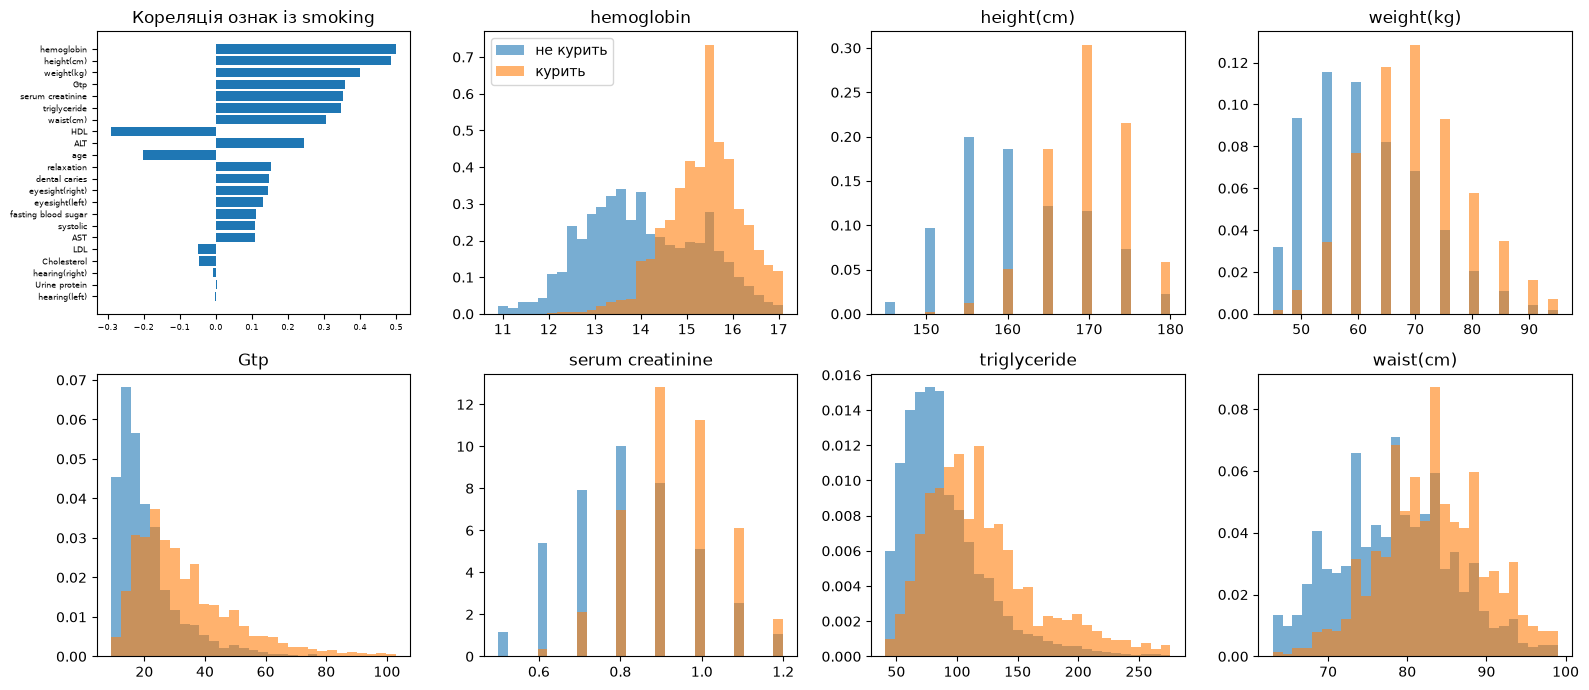

In [2]:
corr = np.array([np.corrcoef(X[:, j], y)[0, 1] for j in range(X.shape[1])])
order = np.argsort(np.abs(corr))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes[0, 0].barh([features[j] for j in order], corr[order])
axes[0, 0].set_title("Кореляція ознак із smoking")
axes[0, 0].tick_params(labelsize=6)
for ax, j in zip(axes.flat[1:], order[::-1]):
    bins = np.linspace(*np.percentile(X[:, j], [1, 99]), 30)
    ax.hist(X[y == 0, j], bins=bins, alpha=0.6, density=True, label="не курить")
    ax.hist(X[y == 1, j], bins=bins, alpha=0.6, density=True, label="курить")
    ax.set_title(features[j])
axes[0, 1].legend()
plt.tight_layout()
plt.show()

Розділимо дані на навчальну (80%) та валідаційну (20%) частини і стандартизуємо ознаки за статистиками навчальної частини.

In [3]:
perm = np.random.default_rng(42).permutation(len(X))
va, tr = perm[: len(X) // 5], perm[len(X) // 5 :]
mean, std = X[tr].mean(axis=0), X[tr].std(axis=0)
X_tr, X_va, X_te = ((A - mean) / std for A in (X[tr], X[va], X_test))
y_tr, y_va = y[tr], y[va]

## 2. Реалізація мережі
Функції активації та їхні похідні:
- `sigmoid`: $\sigma(z)$, $\sigma'(z) = \sigma(z)(1 - \sigma(z))$
- `tanh`: $\tanh(z)$, $\tanh'(z) = 1 - \tanh^2(z)$
- `relu`: $\max(0, z)$, похідна $\mathbb{I}[z > 0]$
- власна функція `swish`: $\phi(z) = z \, \sigma(z)$, $\phi'(z) = \sigma(z)\left(1 + z(1 - \sigma(z))\right)$

In [4]:
def sigmoid(z: np.ndarray) -> np.ndarray:
    return 1.0 / (1.0 + np.exp(-z))


# name: (phi(z), phi'(z))
ACTIVATIONS = {
    "sigmoid": (sigmoid, lambda z: sigmoid(z) * (1 - sigmoid(z))),
    "tanh": (np.tanh, lambda z: 1 - np.tanh(z) ** 2),
    "relu": (lambda z: np.maximum(0, z), lambda z: (z > 0).astype(float)),
    "swish": (lambda z: z * sigmoid(z), lambda z: sigmoid(z) * (1 + z * (1 - sigmoid(z)))),
}


class MLP:
    def __init__(self, d_in: int, d_hidden: int, activation: str, seed: int = 42):
        rng = np.random.default_rng(seed)
        self.act, self.act_grad = ACTIVATIONS[activation]
        self.W1 = rng.normal(0, np.sqrt(1 / d_in), (d_in, d_hidden))
        self.b1 = np.zeros(d_hidden)
        self.W2 = rng.normal(0, np.sqrt(1 / d_hidden), (d_hidden, 1))
        self.b2 = np.zeros(1)

    def forward(self, X: np.ndarray) -> np.ndarray:
        self.X, self.z1 = X, X @ self.W1 + self.b1
        self.a1 = self.act(self.z1)
        return sigmoid(self.a1 @ self.W2 + self.b2).ravel()

    def backward(self, y: np.ndarray, p: np.ndarray, lr: float) -> None:
        dz2 = ((p - y) / len(y))[:, None]
        dz1 = dz2 @ self.W2.T * self.act_grad(self.z1)
        self.W2 -= lr * self.a1.T @ dz2
        self.b2 -= lr * dz2.sum(axis=0)
        self.W1 -= lr * self.X.T @ dz1
        self.b1 -= lr * dz1.sum(axis=0)


def bce(y: np.ndarray, p: np.ndarray) -> float:
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def accuracy(y: np.ndarray, p: np.ndarray) -> float:
    return float(np.mean((p > 0.5) == y))


def roc_auc(y: np.ndarray, p: np.ndarray) -> float:
    # Mann-Whitney U statistic computed from the ranks of positive samples
    ranks = np.argsort(np.argsort(p)) + 1
    n_pos, n_neg = y.sum(), len(y) - y.sum()
    return float((ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def train_mlp(X_tr, y_tr, X_va, y_va, activation, hidden=32, epochs=30, lr=0.1, batch=64, seed=42):
    model = MLP(X_tr.shape[1], hidden, activation, seed)
    rng = np.random.default_rng(seed)
    history = {"loss": [], "acc": []}
    for _ in range(epochs):
        perm = rng.permutation(len(X_tr))
        for i in range(0, len(perm), batch):
            idx = perm[i : i + batch]
            model.backward(y_tr[idx], model.forward(X_tr[idx]), lr)
        p = model.forward(X_va)
        history["loss"].append(bce(y_va, p))
        history["acc"].append(accuracy(y_va, p))
    return model, history

## 3. Порівняння функцій активації
Навчимо однакову мережу (32 нейрони у прихованому шарі, міні-батчевий градієнтний спуск) з кожною функцією активації та порівняємо збіжність і точність на валідації.

Активація  |    BCE | Accuracy | ROC AUC


sigmoid    | 0.4001 |   0.7983 |  0.8826


tanh       | 0.3927 |   0.8013 |  0.8887


relu       | 0.3920 |   0.8080 |  0.8894


swish      | 0.3906 |   0.8027 |  0.8902


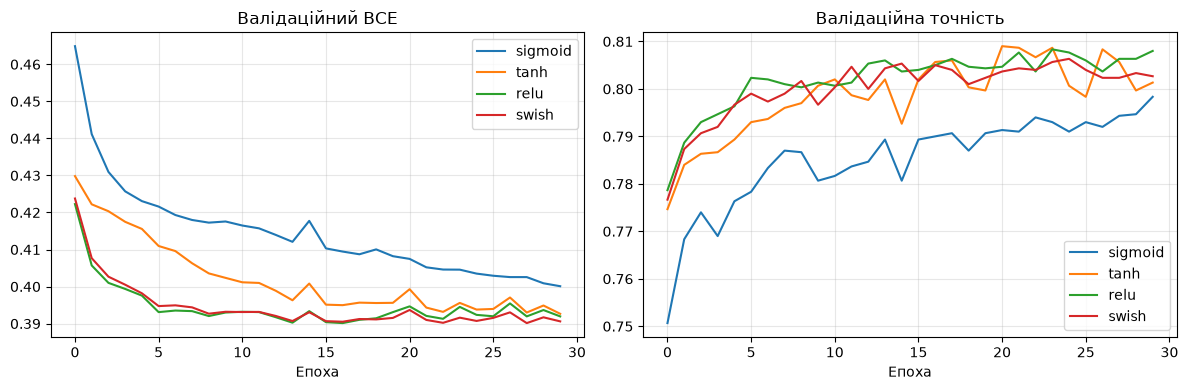

In [5]:
models = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
print(f"{'Активація':<10} | {'BCE':>6} | {'Accuracy':>8} | {'ROC AUC':>7}")
for name in ACTIVATIONS:
    models[name], hist = train_mlp(X_tr, y_tr, X_va, y_va, name)
    p = models[name].forward(X_va)
    print(f"{name:<10} | {bce(y_va, p):6.4f} | {accuracy(y_va, p):8.4f} | {roc_auc(y_va, p):7.4f}")
    axes[0].plot(hist["loss"], label=name)
    axes[1].plot(hist["acc"], label=name)
for ax, title in zip(axes, ("Валідаційний BCE", "Валідаційна точність")):
    ax.set_title(title)
    ax.set_xlabel("Епоха")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Границі рішень
Спроєктуємо ознаки на дві головні компоненти (PCA через SVD), навчимо мережу на цій 2D-проєкції та зобразимо передбачену ймовірність на площині.

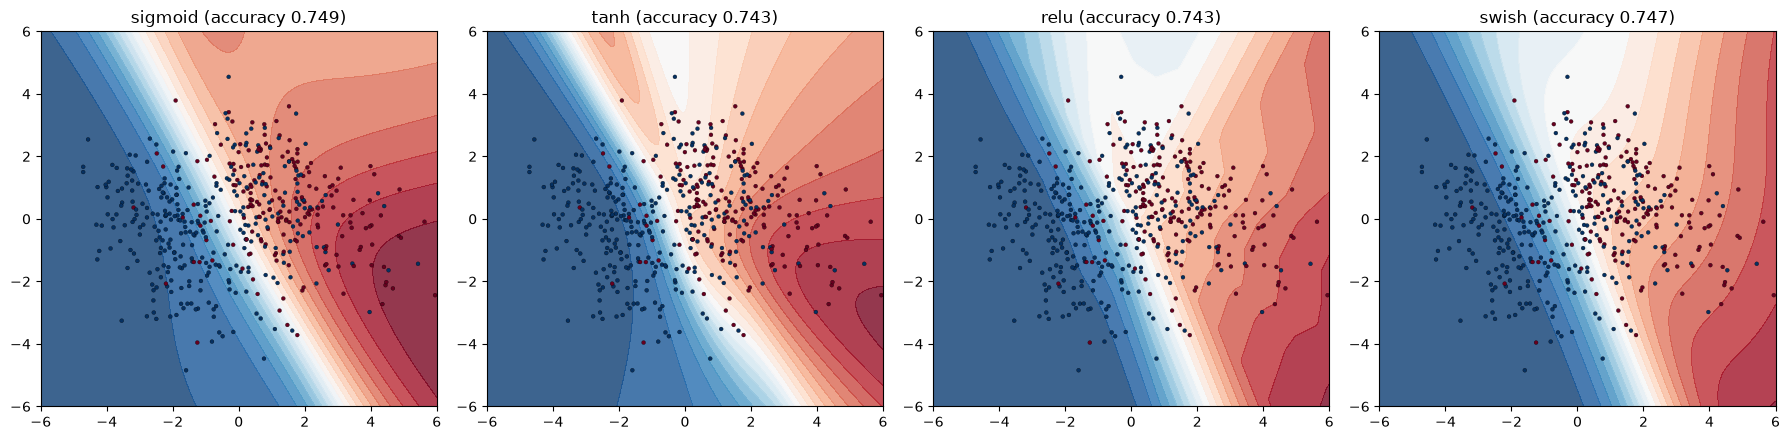

In [6]:
_, _, Vt = np.linalg.svd(X_tr, full_matrices=False)
Z_tr, Z_va = X_tr @ Vt[:2].T, X_va @ Vt[:2].T

xx, yy = np.meshgrid(np.linspace(-6, 6, 200), np.linspace(-6, 6, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, name in zip(axes, ACTIVATIONS):
    model, hist = train_mlp(Z_tr, y_tr, Z_va, y_va, name)
    ax.contourf(xx, yy, model.forward(grid).reshape(xx.shape), levels=20, cmap="RdBu_r", alpha=0.8)
    ax.scatter(Z_va[:500, 0], Z_va[:500, 1], c=y_va[:500], cmap="RdBu_r", s=8, edgecolors="k", linewidths=0.2)
    ax.set_title(f"{name} (accuracy {hist['acc'][-1]:.3f})")
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
plt.tight_layout()
plt.show()

## 5. Формування `submission.csv`
Для прогнозу на тестовій вибірці використаємо модель із найвищим валідаційним ROC AUC.

In [7]:
best = max(models, key=lambda name: roc_auc(y_va, models[name].forward(X_va)))
np.savetxt(
    "submission.csv",
    np.column_stack([test_ids, models[best].forward(X_te)]),
    delimiter=",", header="id,smoking", comments="", fmt=["%d", "%.6f"],
)
print(f"Найкраща активація: {best}, submission.csv збережено")

Найкраща активація: swish, submission.csv збережено


Результат відправки `submission.csv` на Kaggle (вивід Kaggle CLI):

In [ ]:
!kaggle competitions submissions -c deep-learning-lab-1-2025

     ref  fileName        date                        description       status                     publicScore  privateScore  
--------  --------------  --------------------------  ----------------  -------------------------  -----------  ------------  
58844823  submission.csv  2026-11-24 18:23:22.270000  Lab 1 submission  SubmissionStatus.COMPLETE  0.88689      0.88601       


## Висновки
1. Мережу з одним прихованим шаром (32 нейрони), пряме поширення, бінарну крос-ентропію та зворотне поширення реалізовано лише засобами NumPy.
2. Дослідження даних показало, що найсильніше з курінням пов'язані `hemoglobin`, `height(cm)` та `weight(kg)` (кореляція 0.4..0.5), а `HDL` має найбільшу від'ємну кореляцію (близько -0.3).
3. `sigmoid` збігається найповільніше і після 30 епох дає найгірший результат: BCE 0.4001, точність 0.798, ROC AUC 0.8826. Активації `tanh`, `relu` та `swish` близькі між собою: BCE 0.391..0.393, точність 0.801..0.808, ROC AUC 0.889..0.890. Найвищу точність має `relu` (0.808), найвищий ROC AUC має власна активація `swish` (0.8902), тому її використано для `submission.csv`.
4. На 2D-проєкції PCA границі рішень усіх активацій майже лінійні та відрізняються лише на периферії, де даних мало. Точність на двох компонентах (0.74..0.75) нижча, ніж на всіх 22 ознаках (близько 0.80), бо проєкція втрачає частину інформації.